In [1]:
!tar -xf /kaggle/input/datasets/dschettler8845/brats-2021-task1/BraTS2021_Training_Data.tar -C /kaggle/working/

In [2]:
# Cell 1: Import all necessary libraries
import tensorflow as tf
from tensorflow.keras import layers, Model, Input, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import tensorflow.keras.backend as K
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import pandas as pd
import json
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
# Cell 2: Attention Gate Implementation (Improved version)
def attention_gate(g, x, num_filters):
    """
    Attention Gate for focusing on relevant features
    g: gating signal (from decoder) - already at target spatial dimensions
    x: skip connection (from encoder) - same spatial dimensions as g
    num_filters: number of filters in attention layer
    """
    # Ensure inputs have matching spatial dimensions
    # Get spatial dimensions
    g_shape = K.int_shape(g)
    x_shape = K.int_shape(x)
    
    # If dimensions don't match, adjust x (shouldn't happen with proper upsampling)
    if g_shape[1:4] != x_shape[1:4]:
        # Upsample or downsample x to match g's dimensions
        from tensorflow.keras.layers import UpSampling3D, MaxPooling3D
        if g_shape[1] > x_shape[1]:
            x = UpSampling3D(size=(2,2,2))(x)
        elif g_shape[1] < x_shape[1]:
            x = MaxPooling3D(pool_size=(2,2,2))(x)
    
    # Gating signal transformation (1x1x1 convolution to match number of filters)
    theta_x = layers.Conv3D(num_filters, (1,1,1), padding='same')(x)
    
    # Skip connection transformation (1x1x1 convolution)
    phi_g = layers.Conv3D(num_filters, (1,1,1), padding='same')(g)
    
    # Add and activate
    add = layers.Add()([theta_x, phi_g])
    relu = layers.Activation('relu')(add)
    
    # Generate attention coefficients
    psi = layers.Conv3D(1, (1,1,1), padding='same')(relu)
    sigmoid = layers.Activation('sigmoid')(psi)
    
    # Apply attention to original skip connection
    attended_x = layers.Multiply()([x, sigmoid])
    
    return attended_x

print("Improved attention gate defined successfully")

Improved attention gate defined successfully


In [4]:
# Cell 3: Convolution Block with optional attention
def conv_block_with_attention(inputs, num_filters, use_attention=False, gating_signal=None, kernel_size=3, regularizer=None):
    """Conv block with optional attention gate"""
    x = layers.Conv3D(num_filters, kernel_size, padding='same', 
                      kernel_initializer='he_normal', kernel_regularizer=regularizer)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    
    x = layers.Conv3D(num_filters, kernel_size, padding='same', 
                      kernel_initializer='he_normal', kernel_regularizer=regularizer)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    
    # Apply attention if requested
    if use_attention and gating_signal is not None:
        x = attention_gate(gating_signal, x, num_filters)
    
    return x

print("Convolution block defined successfully")

Convolution block defined successfully


In [5]:
# Cell 4: Create 3D U-Net with optional attention gates (FIXED VERSION)
def create_attention_3d_unet(input_shape, num_classes=4, use_attention=True):
    """
    Create 3D U-Net with optional attention gates
    Fixed: Proper handling of spatial dimensions in attention gates
    """
    reg = regularizers.l2(1e-5)
    
    inputs = Input(input_shape)
    
    # Encoder path
    # Level 1: Input -> 112x112x112
    s1 = conv_block_with_attention(inputs, 32, use_attention=False, regularizer=reg)
    p1 = layers.MaxPooling3D((2,2,2))(s1)  # 56x56x56
    p1 = layers.SpatialDropout3D(0.05)(p1)
    
    # Level 2: 56x56x56
    s2 = conv_block_with_attention(p1, 64, use_attention=False, regularizer=reg)
    p2 = layers.MaxPooling3D((2,2,2))(s2)  # 28x28x28
    p2 = layers.SpatialDropout3D(0.1)(p2)
    
    # Level 3: 28x28x28
    s3 = conv_block_with_attention(p2, 128, use_attention=False, regularizer=reg)
    p3 = layers.MaxPooling3D((2,2,2))(s3)  # 14x14x14
    p3 = layers.SpatialDropout3D(0.15)(p3)
    
    # Level 4: 14x14x14
    s4 = conv_block_with_attention(p3, 256, use_attention=False, regularizer=reg)
    p4 = layers.MaxPooling3D((2,2,2))(s4)  # 7x7x7
    p4 = layers.SpatialDropout3D(0.2)(p4)
    
    # Bottleneck: 7x7x7
    b1 = conv_block_with_attention(p4, 512, use_attention=False, regularizer=reg)
    
    # Decoder path with attention gates
    # Level 4: Upsample 7x7x7 -> 14x14x14
    d1 = layers.Conv3DTranspose(256, 2, strides=(2,2,2), padding='same', 
                                 kernel_initializer='he_normal', kernel_regularizer=reg)(b1)
    # s4 is 14x14x14, d1 is 14x14x14 - now they match!
    if use_attention:
        s4_attended = attention_gate(d1, s4, 256)
    else:
        s4_attended = s4
    d1 = layers.concatenate([d1, s4_attended])
    d1 = conv_block_with_attention(d1, 256, use_attention=False, regularizer=reg)
    
    # Level 3: Upsample 14x14x14 -> 28x28x28
    d2 = layers.Conv3DTranspose(128, 2, strides=(2,2,2), padding='same',
                                 kernel_initializer='he_normal', kernel_regularizer=reg)(d1)
    # s3 is 28x28x28, d2 is 28x28x28 - they match!
    if use_attention:
        s3_attended = attention_gate(d2, s3, 128)
    else:
        s3_attended = s3
    d2 = layers.concatenate([d2, s3_attended])
    d2 = conv_block_with_attention(d2, 128, use_attention=False, regularizer=reg)
    
    # Level 2: Upsample 28x28x28 -> 56x56x56
    d3 = layers.Conv3DTranspose(64, 2, strides=(2,2,2), padding='same',
                                 kernel_initializer='he_normal', kernel_regularizer=reg)(d2)
    # s2 is 56x56x56, d3 is 56x56x56 - they match!
    if use_attention:
        s2_attended = attention_gate(d3, s2, 64)
    else:
        s2_attended = s2
    d3 = layers.concatenate([d3, s2_attended])
    d3 = conv_block_with_attention(d3, 64, use_attention=False, regularizer=reg)
    
    # Level 1: Upsample 56x56x56 -> 112x112x112
    d4 = layers.Conv3DTranspose(32, 2, strides=(2,2,2), padding='same',
                                 kernel_initializer='he_normal', kernel_regularizer=reg)(d3)
    # s1 is 112x112x112, d4 is 112x112x112 - they match!
    if use_attention:
        s1_attended = attention_gate(d4, s1, 32)
    else:
        s1_attended = s1
    d4 = layers.concatenate([d4, s1_attended])
    d4 = conv_block_with_attention(d4, 32, use_attention=False, regularizer=reg)
    
    # Output layer
    outputs = layers.Conv3D(num_classes, (1,1,1), activation='softmax')(d4)
    
    model = Model(inputs=[inputs], outputs=[outputs], 
                  name='Attention_3D_U-Net' if use_attention else 'Baseline_3D_U-Net')
    return model

# Test model creation with the fixed version
print("Testing model creation...")
test_model = create_attention_3d_unet((112, 112, 112, 4), num_classes=4, use_attention=True)
test_model.summary()
print(f"\nTotal parameters: {test_model.count_params():,}")
print("Model created successfully!")

Testing model creation...


Model: "Attention_3D_U-Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 112, 112,  │          0 │ -                 │
│ (InputLayer)        │ 112, 4)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d (Conv3D)     │ (None, 112, 112,  │      3,488 │ input_layer[0][0] │
│                     │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        128 │ conv3d[0][0]      │
│ (BatchNormalizatio… │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_1 (Conv3D)   │ (None, 112, 112,  │     27,680 │ activation[0][0]  │
│                     │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv3d_1[0][0]    │
│ (BatchNormalizatio… │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d       │ (None, 56, 56,    │          0 │ activation_1[0][… │
│ (MaxPooling3D)      │ 56, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout3d   │ (None, 56, 56,    │          0 │ max_pooling3d[0]… │
│ (SpatialDropout3D)  │ 56, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_2 (Conv3D)   │ (None, 56, 56,    │     55,360 │ spatial_dropout3… │
│                     │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv3d_2[0][0]    │
│ (BatchNormalizatio… │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_3 (Conv3D)   │ (None, 56, 56,    │    110,656 │ activation_2[0][… │
│                     │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv3d_3[0][0]    │
│ (BatchNormalizatio… │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_1     │ (None, 28, 28,    │          0 │ activation_3[0][… │
│ (MaxPooling3D)      │ 28, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout3d_1 │ (None, 28, 28,    │          0 │ max_pooling3d_1[

 Total params: 22,765,320 (86.84 MB)

 Trainable params: 22,759,432 (86.82 MB)

 Non-trainable params: 5,888 (23.00 KB)


Total parameters: 22,765,320
Model created successfully!


In [6]:
# Cell 5: Fixed Class-Weighted Dice Loss with proper TensorFlow operations
class WeightedDiceLoss:
    """
    Class-weighted Dice Loss for imbalanced tumor classes
    Handles target shape (..., 1) and output shape (..., num_classes)
    """
    def __init__(self, class_weights=None, smooth=1e-6):
        # Default weights emphasizing enhancing tumor (class 3)
        # Format: [background, non-enhancing, edema, enhancing]
        self.class_weights = class_weights or [0.1, 0.2, 0.3, 0.4]
        self.smooth = smooth
    
    def __call__(self, y_true, y_pred):
        # y_true: (batch, H, W, D, 1) with class indices 0-3
        # y_pred: (batch, H, W, D, num_classes) with probabilities
        
        # Remove the last dimension from y_true if it's 1
        if K.ndim(y_true) == 5 and K.int_shape(y_true)[-1] == 1:
            y_true = tf.squeeze(y_true, axis=-1)
        
        # Convert to int32 for one-hot encoding
        y_true = tf.cast(y_true, tf.int32)
        
        # One-hot encode the target
        y_true_oh = tf.one_hot(y_true, depth=len(self.class_weights))
        
        dice_scores = []
        for c in range(len(self.class_weights)):
            y_true_c = y_true_oh[..., c]
            y_pred_c = y_pred[..., c]
            
            intersection = tf.reduce_sum(y_true_c * y_pred_c)
            union = tf.reduce_sum(y_true_c) + tf.reduce_sum(y_pred_c)
            
            dice = (2. * intersection + self.smooth) / (union + self.smooth)
            weighted_dice = self.class_weights[c] * dice
            dice_scores.append(weighted_dice)
        
        return 1.0 - tf.reduce_mean(dice_scores)

def combined_weighted_loss(y_true, y_pred):
    """Combine weighted Dice loss with Categorical Crossentropy"""
    weighted_dice = WeightedDiceLoss()
    dice_loss = weighted_dice(y_true, y_pred)
    
    # Prepare y_true for categorical crossentropy
    if K.ndim(y_true) == 5 and K.int_shape(y_true)[-1] == 1:
        y_true = tf.squeeze(y_true, axis=-1)
    y_true = tf.cast(y_true, tf.int32)
    y_true_oh = tf.one_hot(y_true, depth=4)
    
    ce_loss = tf.keras.losses.categorical_crossentropy(y_true_oh, y_pred)
    ce_loss = tf.reduce_mean(ce_loss)
    
    return 0.5 * dice_loss + 0.5 * ce_loss

print("Fixed loss functions defined successfully")

Fixed loss functions defined successfully


In [7]:
# Cell 6: Fixed metrics using proper TensorFlow operations
import tensorflow as tf

def dice_whole_tumor(y_true, y_pred):
    """Dice for Whole Tumor (labels 1,2,3)"""
    # Handle shape
    if K.ndim(y_true) == 5 and K.int_shape(y_true)[-1] == 1:
        y_true = tf.squeeze(y_true, axis=-1)
    y_true = tf.cast(y_true, tf.int32)
    y_pred_arg = K.argmax(y_pred, axis=-1)
    
    y_true_wt = tf.cast(y_true > 0, tf.float32)
    y_pred_wt = tf.cast(y_pred_arg > 0, tf.float32)
    
    intersection = tf.reduce_sum(y_true_wt * y_pred_wt)
    dice = (2. * intersection + 1e-6) / (tf.reduce_sum(y_true_wt) + tf.reduce_sum(y_pred_wt) + 1e-6)
    return dice

def dice_tumor_core(y_true, y_pred):
    """Dice for Tumor Core (labels 1,3)"""
    if K.ndim(y_true) == 5 and K.int_shape(y_true)[-1] == 1:
        y_true = tf.squeeze(y_true, axis=-1)
    y_true = tf.cast(y_true, tf.int32)
    y_pred_arg = K.argmax(y_pred, axis=-1)
    
    # Use tf.logical_or instead of K.logical_or
    y_true_tc = tf.cast(tf.logical_or(y_true == 1, y_true == 3), tf.float32)
    y_pred_tc = tf.cast(tf.logical_or(y_pred_arg == 1, y_pred_arg == 3), tf.float32)
    
    intersection = tf.reduce_sum(y_true_tc * y_pred_tc)
    dice = (2. * intersection + 1e-6) / (tf.reduce_sum(y_true_tc) + tf.reduce_sum(y_pred_tc) + 1e-6)
    return dice

def dice_enhancing_tumor(y_true, y_pred):
    """Dice for Enhancing Tumor (label 3)"""
    if K.ndim(y_true) == 5 and K.int_shape(y_true)[-1] == 1:
        y_true = tf.squeeze(y_true, axis=-1)
    y_true = tf.cast(y_true, tf.int32)
    y_pred_arg = K.argmax(y_pred, axis=-1)
    
    y_true_et = tf.cast(y_true == 3, tf.float32)
    y_pred_et = tf.cast(y_pred_arg == 3, tf.float32)
    
    intersection = tf.reduce_sum(y_true_et * y_pred_et)
    dice = (2. * intersection + 1e-6) / (tf.reduce_sum(y_true_et) + tf.reduce_sum(y_pred_et) + 1e-6)
    return dice

print("Fixed metrics defined successfully with tf.logical_or")

Fixed metrics defined successfully with tf.logical_or


In [8]:
# Cell 7: Fixed callbacks for training
def get_callbacks(model_path, monitor_metric='val_dice_whole_tumor'):
    """Get standard callbacks for training"""
    return [
        EarlyStopping(monitor='val_loss', patience=15, 
                     restore_best_weights=True, verbose=1),
        ModelCheckpoint(model_path, monitor=monitor_metric,
                       mode='max', save_best_only=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                         patience=8, min_lr=1e-7, verbose=1)
    ]

print("Callbacks function defined")

Callbacks function defined


In [24]:
# Cell 8: Visualization utilities
def visualize_attention_maps(model, test_image, test_mask, save_path='attention_maps.png'):
    """
    Visualize attention coefficient maps from sigmoid layers inside attention gates.
    Works even if attention layers were not explicitly named.
    """

    attention_outputs = []
    layer_names = []

    for layer in model.layers:
        if isinstance(layer, layers.Activation):
            if hasattr(layer, "activation") and layer.activation.__name__ == "sigmoid":
                attention_outputs.append(layer.output)
                layer_names.append(layer.name)

    if not attention_outputs:
        print("No sigmoid attention coefficient layers found.")
        return

    print(f"Found {len(attention_outputs)} attention maps:")
    for name in layer_names:
        print(" -", name)

    attention_model = Model(inputs=model.input, outputs=attention_outputs)

    pred = model.predict(test_image[np.newaxis, ...], verbose=0)
    attention_maps = attention_model.predict(test_image[np.newaxis, ...], verbose=0)

    if not isinstance(attention_maps, list):
        attention_maps = [attention_maps]

    input_mid = test_image.shape[2] // 2

    num_maps = len(attention_maps)
    fig, axes = plt.subplots(2, num_maps + 2, figsize=(5 * (num_maps + 2), 10))

    axes[0, 0].imshow(test_image[:, :, input_mid, 0], cmap="gray")
    axes[0, 0].set_title("Input Image")
    axes[0, 0].axis("off")

    gt = test_mask.squeeze()
    axes[1, 0].imshow(gt[:, :, input_mid], cmap="jet", vmin=0, vmax=3)
    axes[1, 0].set_title("Ground Truth")
    axes[1, 0].axis("off")

    for idx, att_map in enumerate(attention_maps):
        att = att_map[0]

        if att.ndim == 4:
            att = att[..., 0]

        att_mid = att.shape[2] // 2
        att_slice = att[:, :, att_mid]

        axes[0, idx + 1].imshow(att_slice, cmap="hot")
        axes[0, idx + 1].set_title(f"Attention Map {idx + 1}\n{layer_names[idx]}")
        axes[0, idx + 1].axis("off")

        axes[1, idx + 1].imshow(att_slice, cmap="hot")
        axes[1, idx + 1].set_title(f"Attention Coefficients {idx + 1}")
        axes[1, idx + 1].axis("off")

    pred_mask = np.argmax(pred[0], axis=-1)

    axes[0, -1].imshow(test_image[:, :, input_mid, 0], cmap="gray")
    axes[0, -1].set_title("Input Again")
    axes[0, -1].axis("off")

    axes[1, -1].imshow(pred_mask[:, :, input_mid], cmap="jet", vmin=0, vmax=3)
    axes[1, -1].set_title("Prediction")
    axes[1, -1].axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Attention maps saved to {save_path}")
    
def plot_training_comparison(histories, save_path='training_comparison.png'):
    """
    Compare training curves across different model configurations
    """
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    metrics = ['loss', 'dice_whole_tumor', 'dice_tumor_core', 'dice_enhancing_tumor']
    titles = ['Loss', 'Whole Tumor Dice', 'Tumor Core Dice', 'Enhancing Tumor Dice']
    
    colors = {'baseline': 'blue', 'attention': 'green', 'weighted': 'red'}
    
    for idx, (metric, title) in enumerate(zip(metrics, titles)):
        ax = axes[idx // 3, idx % 3]
        
        for model_name, history in histories.items():
            if metric in history.history:
                ax.plot(history.history[metric], label=f'{model_name} Train', 
                       color=colors[model_name], linestyle='-', alpha=0.7)
                if f'val_{metric}' in history.history:
                    ax.plot(history.history[f'val_{metric}'], 
                           label=f'{model_name} Val', color=colors[model_name], 
                           linestyle='--', alpha=0.7)
        
        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    axes[1, 2].axis('off')
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

print("Visualization functions defined")

Visualization functions defined


In [10]:
# Cell 9: Fixed model evaluation function with numpy-based metrics (no tensor errors)
def evaluate_model(model, val_gen, model_name, num_batches=20):
    """Evaluate model using numpy operations - avoids tensor shape errors"""
    wt_dice_scores = []
    tc_dice_scores = []
    et_dice_scores = []
    
    print(f"\nEvaluating {model_name}...")
    
    for batch_idx in range(min(num_batches, len(val_gen))):
        try:
            # Get batch
            X, y = val_gen[batch_idx]
            
            # Predict
            pred = model.predict(X, verbose=0)
            
            # Convert to numpy
            if isinstance(y, tf.Tensor):
                y_np = y.numpy()
            else:
                y_np = y
            
            if isinstance(pred, tf.Tensor):
                pred_np = pred.numpy()
            else:
                pred_np = pred
            
            # Squeeze mask if needed (remove channel dimension)
            if y_np.ndim == 5 and y_np.shape[-1] == 1:
                y_np = y_np.squeeze(axis=-1)
            
            # Get predicted classes
            y_pred_arg = np.argmax(pred_np, axis=-1)
            
            # Calculate Whole Tumor Dice (classes 1,2,3)
            y_true_wt = (y_np > 0).astype(np.float32)
            y_pred_wt = (y_pred_arg > 0).astype(np.float32)
            intersection_wt = np.sum(y_true_wt * y_pred_wt)
            union_wt = np.sum(y_true_wt) + np.sum(y_pred_wt)
            wt_dice = (2.0 * intersection_wt + 1e-6) / (union_wt + 1e-6)
            
            # Calculate Tumor Core Dice (classes 1,3)
            y_true_tc = np.logical_or(y_np == 1, y_np == 3).astype(np.float32)
            y_pred_tc = np.logical_or(y_pred_arg == 1, y_pred_arg == 3).astype(np.float32)
            intersection_tc = np.sum(y_true_tc * y_pred_tc)
            union_tc = np.sum(y_true_tc) + np.sum(y_pred_tc)
            tc_dice = (2.0 * intersection_tc + 1e-6) / (union_tc + 1e-6)
            
            # Calculate Enhancing Tumor Dice (class 3)
            y_true_et = (y_np == 3).astype(np.float32)
            y_pred_et = (y_pred_arg == 3).astype(np.float32)
            intersection_et = np.sum(y_true_et * y_pred_et)
            union_et = np.sum(y_true_et) + np.sum(y_pred_et)
            et_dice = (2.0 * intersection_et + 1e-6) / (union_et + 1e-6)
            
            wt_dice_scores.append(wt_dice)
            tc_dice_scores.append(tc_dice)
            et_dice_scores.append(et_dice)
            
            if batch_idx % 5 == 0:
                print(f"  Batch {batch_idx}: WT={wt_dice:.3f}, TC={tc_dice:.3f}, ET={et_dice:.3f}")
                
        except Exception as e:
            print(f"  Warning: Batch {batch_idx} failed: {e}")
            continue
    
    # Calculate averages
    results = {
        'whole_tumor_dice': np.mean(wt_dice_scores) if wt_dice_scores else 0,
        'tumor_core_dice': np.mean(tc_dice_scores) if tc_dice_scores else 0,
        'enhancing_tumor_dice': np.mean(et_dice_scores) if et_dice_scores else 0
    }
    
    print(f"\n{model_name} Final Results (based on {len(wt_dice_scores)} batches):")
    print(f"  Whole Tumor Dice: {results['whole_tumor_dice']:.4f}")
    print(f"  Tumor Core Dice: {results['tumor_core_dice']:.4f}")
    print(f"  Enhancing Tumor Dice: {results['enhancing_tumor_dice']:.4f}")
    
    return results

In [11]:
# Cell 10: Attention-only training function

def train_attention_model_only(train_gen, val_gen, patch_size, num_classes=4, epochs=20):
    model_path = "attention_model.keras"

    print("=" * 50)
    print("Training ATTENTION model only")
    print("=" * 50)

    models = {}
    histories = {}
    results = {}

    if Path(model_path).exists():
        print(f"Loading existing attention model from {model_path}")
        from tensorflow.keras.models import load_model

        attention_model = load_model(model_path, compile=False)
        attention_model.compile(
            optimizer=Adam(learning_rate=1e-4),
            loss="sparse_categorical_crossentropy",
            metrics=[
                "accuracy",
                dice_whole_tumor,
                dice_tumor_core,
                dice_enhancing_tumor
            ]
        )

        attention_history = None

    else:
        attention_model = create_attention_3d_unet(
            input_shape=(*patch_size, 4),
            num_classes=num_classes,
            use_attention=True
        )

        attention_model.compile(
            optimizer=Adam(learning_rate=1e-4),
            loss="sparse_categorical_crossentropy",
            metrics=[
                "accuracy",
                dice_whole_tumor,
                dice_tumor_core,
                dice_enhancing_tumor
            ]
        )

        attention_model.summary()

        attention_history = attention_model.fit(
            train_gen,
            validation_data=val_gen,
            epochs=epochs,
            callbacks=get_callbacks(model_path),
            verbose=1
        )

    attention_metrics = evaluate_model(
        attention_model,
        val_gen,
        "Attention Model"
    )

    models["attention"] = attention_model
    histories["attention"] = attention_history
    results["attention"] = attention_metrics

    return results, histories, models

In [12]:
# Cell 12
import warnings
from pathlib import Path
from typing import Dict, Tuple, List

import json
import numpy as np
import pandas as pd
import nibabel as nib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import (
    Conv3D, MaxPooling3D, Conv3DTranspose, Input,
    BatchNormalization, Activation, SpatialDropout3D, concatenate
)
from tensorflow.keras import regularizers, initializers
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

In [13]:
# Cell 13
USE_FLOAT16 = True
MODALITIES = ["t1", "t1ce", "t2", "flair"]

def load_nifti_canonical(path: Path) -> Tuple[np.ndarray, np.ndarray, dict]:
    nii = nib.as_closest_canonical(nib.load(str(path)))
    data = nii.get_fdata(dtype=np.float32)
    affine = nii.affine
    header = {k: nii.header[k].tolist() if k in nii.header else None for k in ["dim", "pixdim"]}
    return data, affine, header

def normalize_nonzero(volume: np.ndarray) -> np.ndarray:
    vol = volume.astype(np.float32)
    nz = vol[vol != 0]
    if nz.size > 0:
        mean, std = float(nz.mean()), float(nz.std())
    else:
        mean, std = float(vol.mean()), float(vol.std())
    vol = (vol - mean) / (std + 1e-8)
    return vol

def preprocess_mask_multiclass(mask: np.ndarray) -> np.ndarray:
    m = np.rint(mask).astype(np.uint8)
    m[m == 4] = 3
    return m

def crop_to_roi(image: np.ndarray, mask: np.ndarray, margin: int = 5) -> Tuple[np.ndarray, np.ndarray]:
    coords = np.array(np.nonzero(mask))
    if coords.size == 0:
        return image, mask
    zmin, ymin, xmin = coords.min(axis=1)
    zmax, ymax, xmax = coords.max(axis=1)
    zmin = max(zmin - margin, 0)
    ymin = max(ymin - margin, 0)
    xmin = max(xmin - margin, 0)
    zmax = min(zmax + margin, mask.shape[0] - 1)
    ymax = min(ymax + margin, mask.shape[1] - 1)
    xmax = min(xmax + margin, mask.shape[2] - 1)
    img_c = image[zmin:zmax+1, ymin:ymax+1, xmin:xmax+1]
    msk_c = mask[zmin:zmax+1, ymin:ymax+1, xmin:xmax+1]
    return img_c, msk_c

def process_one_patient(patient_folder: Path, patient_id: str) -> Tuple[np.ndarray, np.ndarray, Dict]:
    mask_path = patient_folder / f"{patient_id}_seg.nii.gz"
    if not mask_path.exists():
        raise FileNotFoundError(f"Mask file not found: {mask_path}")
    mask_vol, aff_m, hdr_m = load_nifti_canonical(mask_path)
    mask = preprocess_mask_multiclass(mask_vol)

    vols = []
    metas = {"patient_id": patient_id, "modalities": MODALITIES}
    for mod in MODALITIES:
        p = patient_folder / f"{patient_id}_{mod}.nii.gz"
        if not p.exists():
            raise FileNotFoundError(f"File not found: {p}")
        vol, aff, hdr = load_nifti_canonical(p)
        vols.append(vol)
        metas[f"affine_{mod}"] = aff.tolist()
        metas[f"header_{mod}"] = hdr

    shapes = [v.shape for v in vols]
    if len(set(shapes)) != 1:
        raise ValueError(f"[AlignmentError] Modality shapes differ for patient {patient_id}: {shapes}")

    image_4ch = np.stack(vols, axis=-1)
    image_4ch, mask = crop_to_roi(image_4ch, mask)

    for i in range(image_4ch.shape[-1]):
        image_4ch[..., i] = normalize_nonzero(image_4ch[..., i])

    if USE_FLOAT16:
        image_4ch = image_4ch.astype(np.float16)

    metas["affine_mask"] = aff_m.tolist()
    metas["header_mask"] = hdr_m
    metas["shape"] = list(mask.shape)

    return image_4ch, mask, metas

DATA_DIR = Path(r"/kaggle/working/")  
SAVE_DIR = Path(r"/kaggle/working/BraTS2021_Preprocessed")  
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# --- Data Loading and Preprocessing ---
def run_preprocessing(data_dir: Path, save_dir: Path) -> pd.DataFrame:
    patient_folders = [p for p in data_dir.iterdir() if p.is_dir()]
    records = []
    for p_folder in patient_folders:
        patient_id = p_folder.name
        try:
            img, msk, meta = process_one_patient(p_folder, patient_id)
            
            img_path = save_dir / f"{patient_id}_img.npy"
            msk_path = save_dir / f"{patient_id}_msk.npy"
            meta_path = save_dir / f"{patient_id}_meta.json"

            np.save(img_path, img)
            np.save(msk_path, msk)
            with open(meta_path, 'w') as f:
                json.dump(meta, f)

            records.append({
                'patient_id': patient_id,
                'image_path': str(img_path),
                'mask_path': str(msk_path),
                'meta_path': str(meta_path)
            })
        except Exception as e:
            print(f"Error processing patient {patient_id}: {e}")
    return pd.DataFrame(records)


# Check if preprocessing has been done, otherwise run it
preprocessed_manifest = SAVE_DIR / "manifest.csv"
if not preprocessed_manifest.exists():
    print("Running preprocessing...")
    df = run_preprocessing(DATA_DIR, SAVE_DIR)
    df.to_csv(preprocessed_manifest, index=False)
else:
    print("Loading preprocessed manifest...")
    df = pd.read_csv(preprocessed_manifest)

Running preprocessing...
Error processing patient BraTS2021_Preprocessed: Mask file not found: /kaggle/working/BraTS2021_Preprocessed/BraTS2021_Preprocessed_seg.nii.gz
Error processing patient .virtual_documents: Mask file not found: /kaggle/working/.virtual_documents/.virtual_documents_seg.nii.gz


In [14]:
# Cell 14: Load your preprocessed data
# Assuming you've already run your preprocessing code

preprocessed_manifest = SAVE_DIR / "manifest.csv"

# Load the manifest
if preprocessed_manifest.exists():
    df = pd.read_csv(preprocessed_manifest)
    print(f"Loaded {len(df)} patients from manifest")
else:
    print("Please run preprocessing first")
    # Your preprocessing code here

# Split data
train_df, temp_df = train_test_split(df, test_size=0.3, random_state=42, shuffle=True)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42, shuffle=True)

print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Loaded 1251 patients from manifest
Train: 875, Val: 188, Test: 188


In [15]:
# Cell 15
import math

def pad_to_min_shape(arr, min_shape, pad_value=0):
    pad_width = []
    for i, s in enumerate(arr.shape[:3]):
        needed = max(0, min_shape[i] - s)
        before = needed // 2
        after = needed - before
        pad_width.append((before, after))
    if arr.ndim == 4:
        pad_width.append((0, 0))
    return np.pad(arr, pad_width, mode='constant', constant_values=pad_value)

def extract_patch(image, mask, patch_size, center=None):
    h, w, d = image.shape[:3]
    ph, pw, pd = patch_size

    if h < ph or w < pw or d < pd:
        image_p = pad_to_min_shape(image, patch_size, pad_value=0)
        mask_p = pad_to_min_shape(mask, patch_size, pad_value=0)
        h, w, d = image_p.shape[:3]
        y = (h - ph) // 2
        x = (w - pw) // 2
        z = (d - pd) // 2
        return image_p[y:y+ph, x:x+pw, z:z+pd], mask_p[y:y+ph, x:x+pw, z:z+pd]

    if center is None:
        y = np.random.randint(0, h - ph + 1)
        x = np.random.randint(0, w - pw + 1)
        z = np.random.randint(0, d - pd + 1)
    else:
        cy, cx, cz = center
        y = np.clip(cy - ph // 2, 0, h - ph)
        x = np.clip(cx - pw // 2, 0, w - pw)
        z = np.clip(cz - pd // 2, 0, d - pd)

    return image[y:y+ph, x:x+pw, z:z+pd], mask[y:y+ph, x:x+pw, z:z+pd]

def random_flip_3d(img, msk):
    for axis in [0, 1, 2]:
        if np.random.rand() < 0.5:
            img = np.flip(img, axis=axis)
            msk = np.flip(msk, axis=axis)
    return img, msk

def intensity_jitter(img, shift_limit=0.1, scale_limit=0.1):
    out = img.astype(np.float32)
    for c in range(out.shape[-1]):
        scale = 1.0 + np.random.uniform(-scale_limit, scale_limit)
        shift = np.random.uniform(-shift_limit, shift_limit)
        out[..., c] = out[..., c] * scale + shift
    return out

def add_noise(img, std=0.02):
    noise = np.random.normal(0, std, size=img.shape).astype(np.float32)
    return img + noise

class BraTSDataGenerator(keras.utils.Sequence):
    def __init__(self, df, patch_size, batch_size=1, augment=False, shuffle=True, min_tumor_frac=0.01):
        self.df = df.reset_index(drop=True)
        self.patch_size = patch_size
        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle
        self.min_tumor_frac = min_tumor_frac
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.df))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, index):
        idxs = self.indexes[index*self.batch_size:(index+1)*self.batch_size]
        X = np.zeros((self.batch_size, *self.patch_size, 4), dtype=np.float32)
        y = np.zeros((self.batch_size, *self.patch_size, 1), dtype=np.uint8)

        for i, ridx in enumerate(idxs):
            row = self.df.iloc[ridx]
            image = np.load(row['image_path']).astype(np.float32)
            mask = np.load(row['mask_path']).astype(np.uint8)

            tries = 0
            patch_img, patch_msk = None, None
            while tries < 10:
                tumor_coords = np.argwhere(mask > 0)
                if tumor_coords.size > 0:
                    cy, cx, cz = tumor_coords[np.random.randint(0, len(tumor_coords))]
                    center = (cy, cx, cz)
                else:
                    center = None
                patch_img, patch_msk = extract_patch(image, mask, self.patch_size, center=center)
                frac = (patch_msk > 0).mean()
                if frac >= self.min_tumor_frac or tumor_coords.size == 0:
                    break
                tries += 1

            if self.augment:
                patch_img, patch_msk = random_flip_3d(patch_img, patch_msk)
                if np.random.rand() < 0.5:
                    patch_img = intensity_jitter(patch_img)
                if np.random.rand() < 0.5:
                    patch_img = add_noise(patch_img)

            X[i] = patch_img
            y[i] = np.expand_dims(patch_msk, axis=-1)

        return X, y

In [16]:
# Cell 16: Initialize data generators
# Make sure BraTSDataGenerator is defined (from your original code)

PATCH_SIZE = (112, 112, 112)
BATCH_SIZE = 1
NUM_CLASSES = 4
EPOCHS = 20  # Adjust as needed

train_gen = BraTSDataGenerator(train_df, patch_size=PATCH_SIZE, 
                               batch_size=BATCH_SIZE, augment=True, shuffle=True)
val_gen = BraTSDataGenerator(val_df, patch_size=PATCH_SIZE, 
                             batch_size=BATCH_SIZE, augment=False, shuffle=False)

print(f"Train batches: {len(train_gen)}")
print(f"Validation batches: {len(val_gen)}")

Train batches: 875
Validation batches: 188


In [ ]:
# Cell 17: Train attention model only

results, histories, models = train_attention_model_only(
    train_gen,
    val_gen,
    PATCH_SIZE,
    NUM_CLASSES,
    EPOCHS
)

results_df = pd.DataFrame(results).T
results_df.to_csv("attention_model_metrics.csv")

print("\n✓ Results saved to attention_model_metrics.csv")
print(results_df)

Training ATTENTION model only


Model: "Attention_3D_U-Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 112, 112,  │          0 │ -                 │
│ (InputLayer)        │ 112, 4)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_31 (Conv3D)  │ (None, 112, 112,  │      3,488 │ input_layer_1[0]… │
│                     │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv3d_31[0][0]   │
│ (BatchNormalizatio… │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_26       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_32 (Conv3D)  │ (None, 112, 112,  │     27,680 │ activation_26[0]… │
│                     │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv3d_32[0][0]   │
│ (BatchNormalizatio… │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_27       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 112, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_4     │ (None, 56, 56,    │          0 │ activation_27[0]… │
│ (MaxPooling3D)      │ 56, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout3d_4 │ (None, 56, 56,    │          0 │ max_pooling3d_4[… │
│ (SpatialDropout3D)  │ 56, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_33 (Conv3D)  │ (None, 56, 56,    │     55,360 │ spatial_dropout3… │
│                     │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv3d_33[0][0]   │
│ (BatchNormalizatio… │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_28       │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_34 (Conv3D)  │ (None, 56, 56,    │    110,656 │ activation_28[0]… │
│                     │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv3d_34[0][0]   │
│ (BatchNormalizatio… │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_29       │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 56, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_5     │ (None, 28, 28,    │          0 │ activation_29[0]… │
│ (MaxPooling3D)      │ 28, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout3d_5 │ (None, 28, 28,    │          0 │ max_pooling3d_5[

 Total params: 22,765,320 (86.84 MB)

 Trainable params: 22,759,432 (86.82 MB)

 Non-trainable params: 5,888 (23.00 KB)

Epoch 1/20


I0000 00:00:1779861118.115222     103 service.cc:152] XLA service 0x7d343c002280 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779861118.116698     103 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1779861118.116706     103 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1779861121.615963     103 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-05-27 05:52:04.350911: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-27 05:52:04.495811: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-27 05:52:04.638076: E external/local_xl

875/875 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9394 - dice_enhancing_tumor: 0.5340 - dice_tumor_core: 0.5800 - dice_whole_tumor: 0.7778 - loss: 0.4846
Epoch 1: val_dice_whole_tumor improved from -inf to 0.88041, saving model to attention_model.keras
875/875 ━━━━━━━━━━━━━━━━━━━━ 1138s 1s/step - accuracy: 0.9395 - dice_enhancing_tumor: 0.5342 - dice_tumor_core: 0.5801 - dice_whole_tumor: 0.7779 - loss: 0.4844 - val_accuracy: 0.9751 - val_dice_enhancing_tumor: 0.7266 - val_dice_tumor_core: 0.7113 - val_dice_whole_tumor: 0.8804 - val_loss: 0.1609 - learning_rate: 1.0000e-04
Epoch 2/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9778 - dice_enhancing_tumor: 0.7415 - dice_tumor_core: 0.7698 - dice_whole_tumor: 0.8828 - loss: 0.1446
Epoch 2: val_dice_whole_tumor did not improve from 0.88041
875/875 ━━━━━━━━━━━━━━━━━━━━ 1043s 1s/step - accuracy: 0.9778 - dice_enhancing_tumor: 0.7415 - dice_tumor_core: 0.7698 - dice_whole_tumor: 0.8828 - loss: 0.1446 - val_accuracy: 0.9761 - va


ATTENTION MODEL RESULTS
Whole Tumor Dice:      0.9141
Tumor Core Dice:       0.8711
Enhancing Tumor Dice:  0.8292


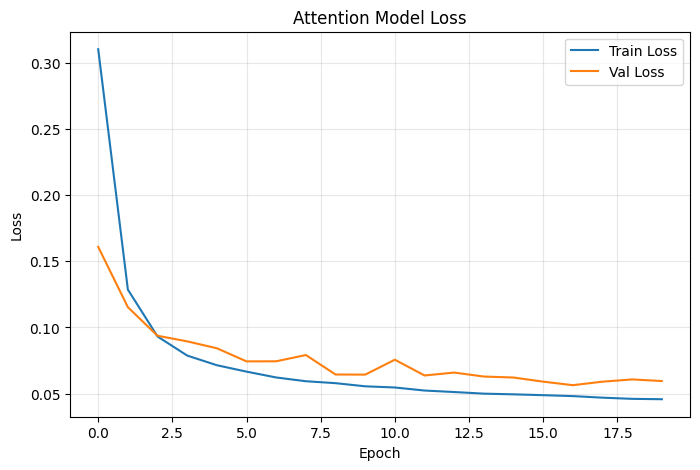

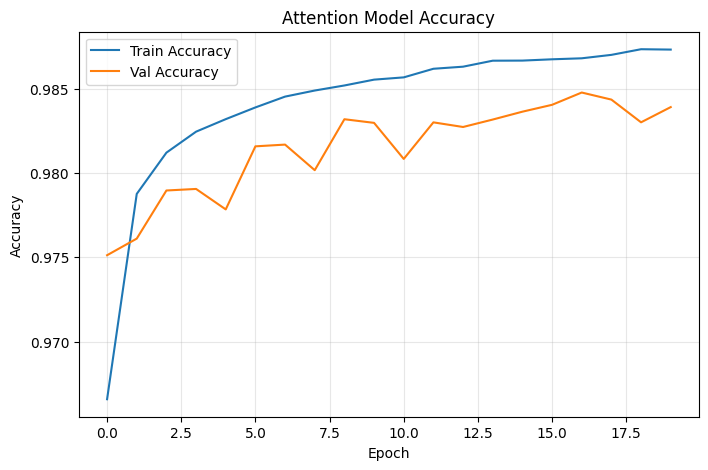

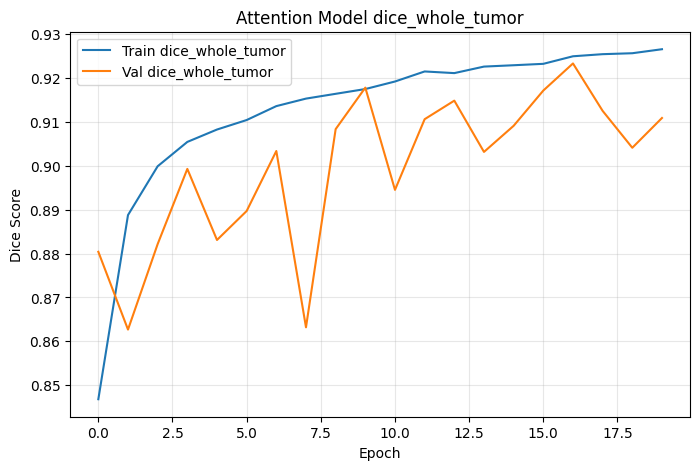

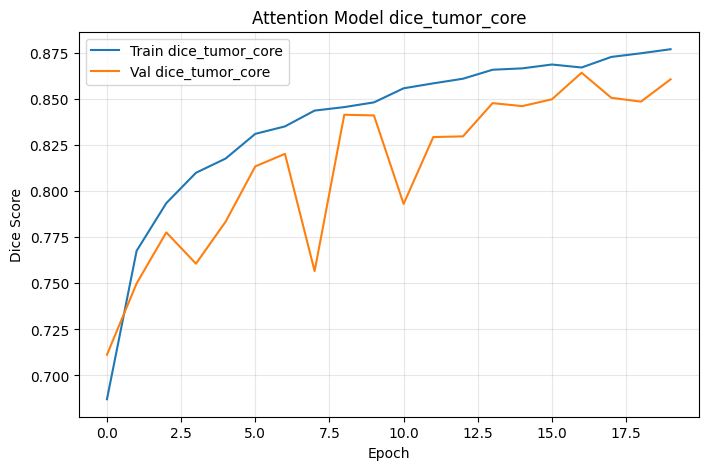

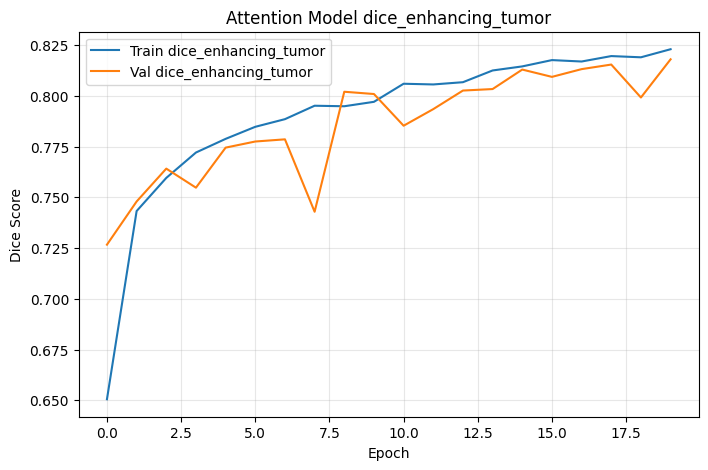

In [ ]:
# Cell 18: Visualize attention model training and metrics

if results:
    print("\n" + "=" * 60)
    print("ATTENTION MODEL RESULTS")
    print("=" * 60)

    metrics = results["attention"]

    print(f"Whole Tumor Dice:      {metrics['whole_tumor_dice']:.4f}")
    print(f"Tumor Core Dice:       {metrics['tumor_core_dice']:.4f}")
    print(f"Enhancing Tumor Dice:  {metrics['enhancing_tumor_dice']:.4f}")

    history = histories.get("attention")

    if history is not None:
        plt.figure(figsize=(8, 5))
        plt.plot(history.history["loss"], label="Train Loss")
        plt.plot(history.history["val_loss"], label="Val Loss")
        plt.title("Attention Model Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.savefig("attention_model_loss.png", dpi=150)
        plt.show()

        plt.figure(figsize=(8, 5))
        plt.plot(history.history["accuracy"], label="Train Accuracy")
        plt.plot(history.history["val_accuracy"], label="Val Accuracy")
        plt.title("Attention Model Accuracy")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.savefig("attention_model_accuracy.png", dpi=150)
        plt.show()

        dice_metrics = [
            "dice_whole_tumor",
            "dice_tumor_core",
            "dice_enhancing_tumor"
        ]

        for metric in dice_metrics:
            if metric in history.history:
                plt.figure(figsize=(8, 5))
                plt.plot(history.history[metric], label=f"Train {metric}")
                plt.plot(history.history[f"val_{metric}"], label=f"Val {metric}")
                plt.title(f"Attention Model {metric}")
                plt.xlabel("Epoch")
                plt.ylabel("Dice Score")
                plt.legend()
                plt.grid(True, alpha=0.3)
                plt.savefig(f"attention_model_{metric}.png", dpi=150)
                plt.show()
    else:
        print("Model was loaded from disk, so no training history is available.")
else:
    print("No results found. Run Cell 17 first.")

Visualizing attention maps for Attention model...
Found 4 attention maps:
 - activation_37
 - activation_41
 - activation_45
 - activation_49


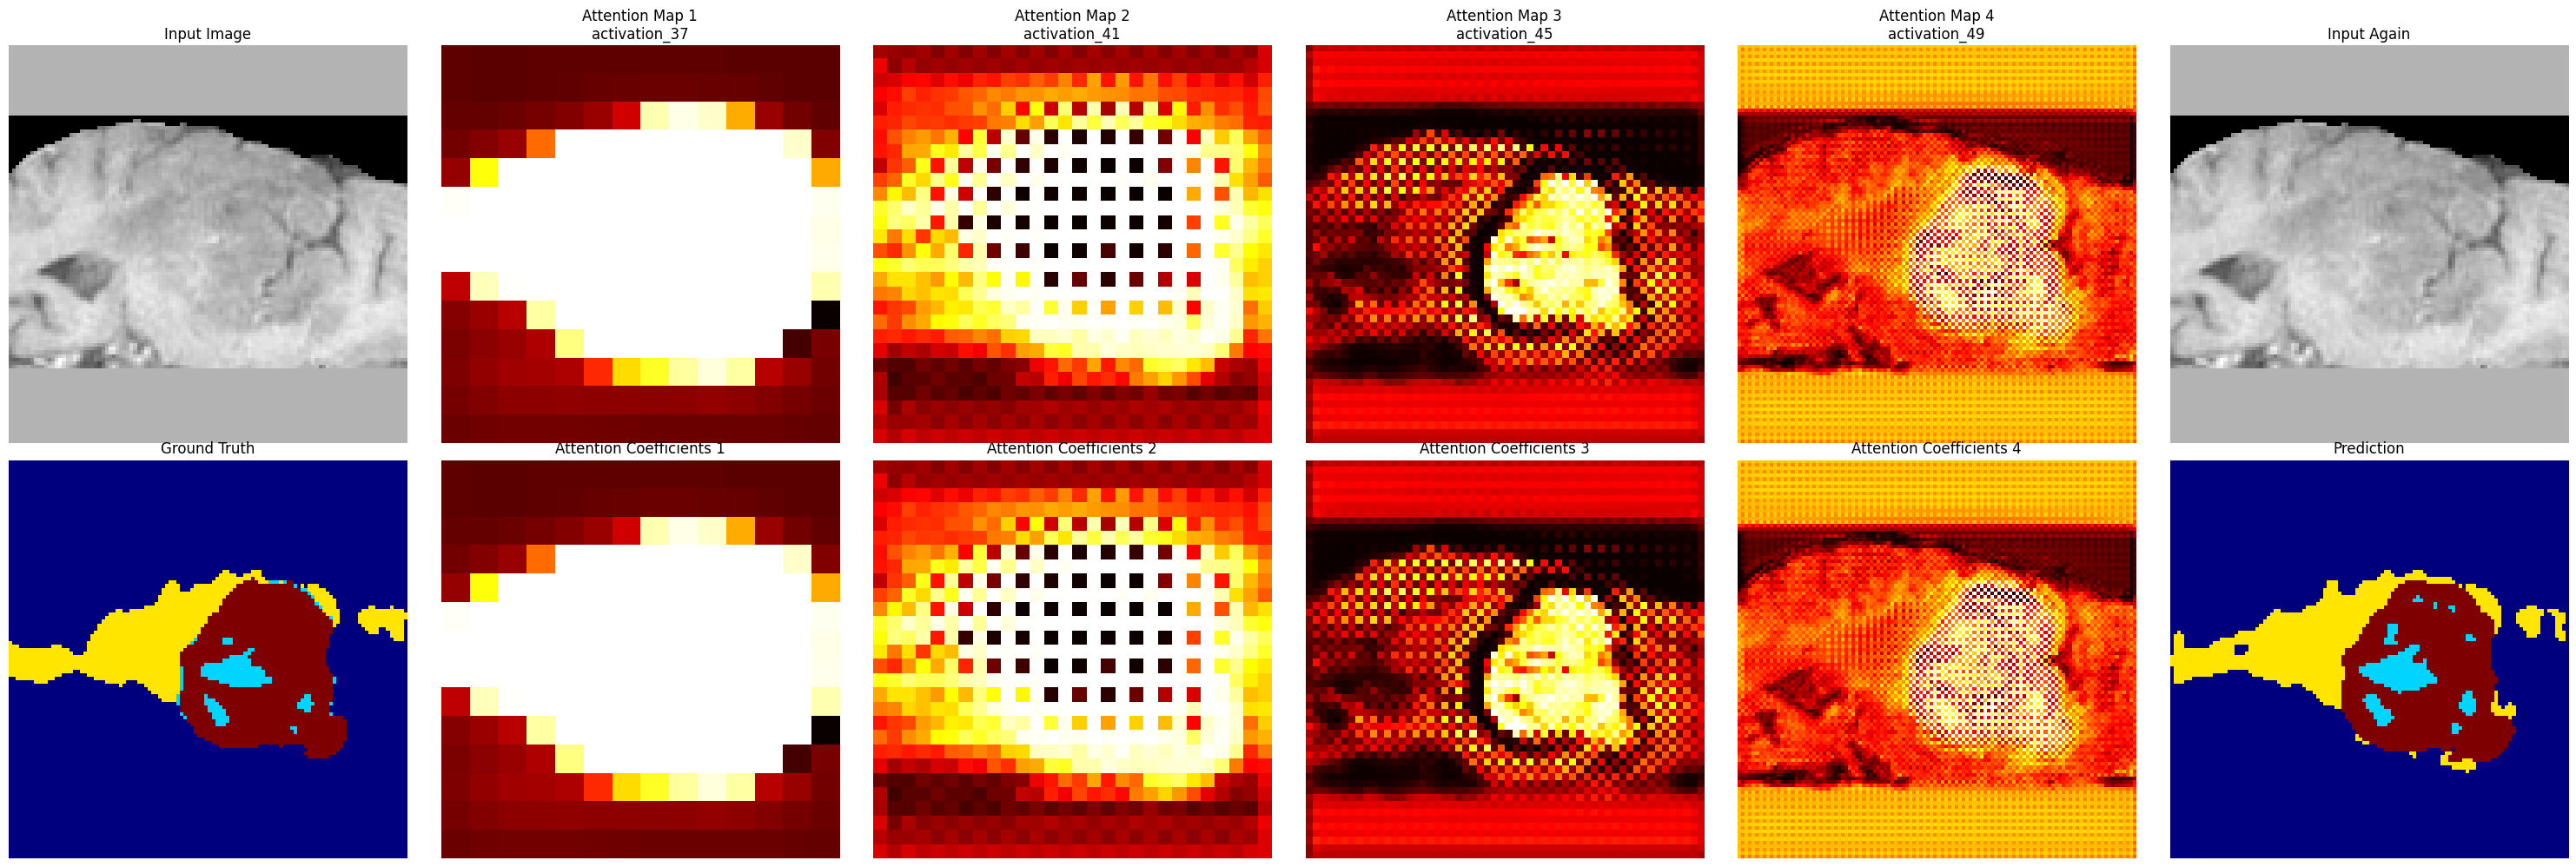

Attention maps saved to attention_maps_sample.png


In [25]:
# Cell 19: Visualize attention maps only

sample_batch = next(iter(val_gen))
sample_image, sample_mask = sample_batch

sample_image_3d = sample_image[0]
sample_mask_3d = sample_mask[0]

if "attention" in models and models["attention"] is not None:
    print("Visualizing attention maps for Attention model...")

    try:
        visualize_attention_maps(
            models["attention"],
            sample_image_3d,
            sample_mask_3d,
            "attention_maps_sample.png"
        )
    except Exception as e:
        print(f"Could not visualize attention maps: {e}")
else:
    print("Attention model not available.")

Computing confidence interval for attention model...


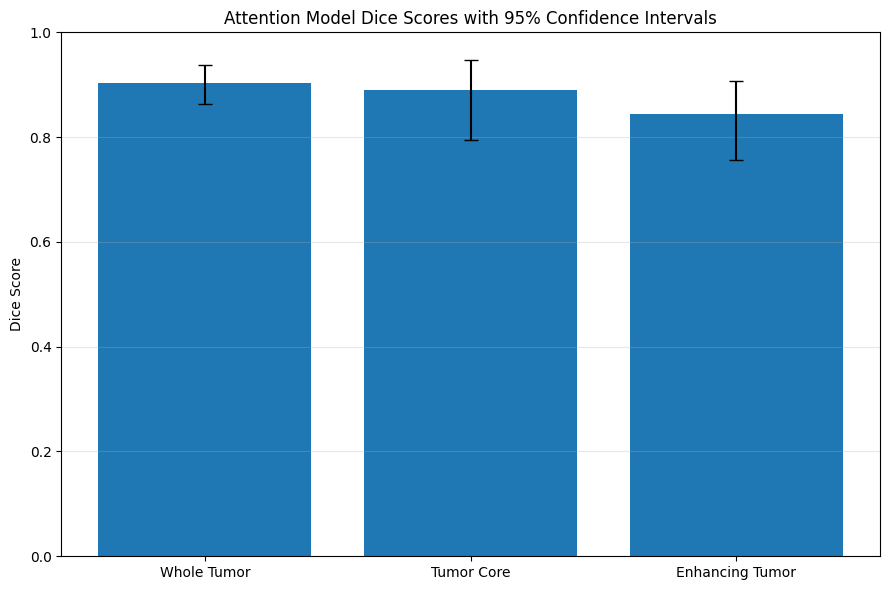

{'wt': {'mean': np.float32(0.90360814), 'lower': np.float32(0.8630756), 'upper': np.float32(0.93709046)}, 'tc': {'mean': np.float32(0.88975775), 'lower': np.float32(0.79410994), 'upper': np.float32(0.94805944)}, 'et': {'mean': np.float32(0.84415334), 'lower': np.float32(0.75632036), 'upper': np.float32(0.9070083)}}


In [22]:
# Cell 20: Confidence intervals for attention model only
def compute_confidence_intervals_safe(model, val_gen, n_bootstrap=50, confidence=0.95):
    """Safe version of confidence intervals with error handling"""
    if model is None:
        print("  Model not available, skipping...")
        return None
    
    try:
        all_predictions = []
        all_ground_truths = []
        
        # Collect predictions (limit to 30 batches for speed)
        n_batches = min(30, len(val_gen))
        for i in range(n_batches):
            X, y = val_gen[i]
            pred = model.predict(X, verbose=0)
            all_predictions.append(pred)
            all_ground_truths.append(y)
        
        all_predictions = np.concatenate(all_predictions, axis=0)
        all_ground_truths = np.concatenate(all_ground_truths, axis=0)
        
        # Bootstrap
        n_samples = len(all_predictions)
        bootstrapped_metrics = {'wt': [], 'tc': [], 'et': []}
        
        for _ in range(min(n_bootstrap, 100)):
            indices = np.random.choice(n_samples, n_samples, replace=True)
            
            wt_scores = []
            tc_scores = []
            et_scores = []
            
            for idx in indices[:20]:  # Limit per bootstrap for speed
                pred = all_predictions[idx:idx+1]
                gt = all_ground_truths[idx:idx+1]
                
                # Numpy-based calculation for speed
                if gt.ndim == 5 and gt.shape[-1] == 1:
                    gt_np = gt.squeeze(axis=-1)
                else:
                    gt_np = gt
                
                pred_arg = np.argmax(pred, axis=-1)
                
                # WT
                wt_true = (gt_np > 0).astype(np.float32)
                wt_pred = (pred_arg > 0).astype(np.float32)
                wt_dice = (2 * np.sum(wt_true * wt_pred) + 1e-6) / (np.sum(wt_true) + np.sum(wt_pred) + 1e-6)
                
                # TC
                tc_true = np.logical_or(gt_np == 1, gt_np == 3).astype(np.float32)
                tc_pred = np.logical_or(pred_arg == 1, pred_arg == 3).astype(np.float32)
                tc_dice = (2 * np.sum(tc_true * tc_pred) + 1e-6) / (np.sum(tc_true) + np.sum(tc_pred) + 1e-6)
                
                # ET
                et_true = (gt_np == 3).astype(np.float32)
                et_pred = (pred_arg == 3).astype(np.float32)
                et_dice = (2 * np.sum(et_true * et_pred) + 1e-6) / (np.sum(et_true) + np.sum(et_pred) + 1e-6)
                
                wt_scores.append(wt_dice)
                tc_scores.append(tc_dice)
                et_scores.append(et_dice)
            
            bootstrapped_metrics['wt'].append(np.mean(wt_scores))
            bootstrapped_metrics['tc'].append(np.mean(tc_scores))
            bootstrapped_metrics['et'].append(np.mean(et_scores))
        
        # Calculate confidence intervals
        alpha = 1 - confidence
        lower_percentile = (alpha / 2) * 100
        upper_percentile = (1 - alpha / 2) * 100
        
        cis = {}
        for metric, values in bootstrapped_metrics.items():
            cis[metric] = {
                'mean': np.mean(values),
                'lower': np.percentile(values, lower_percentile),
                'upper': np.percentile(values, upper_percentile)
            }
        
        return cis
    except Exception as e:
        print(f"  Error computing confidence intervals: {e}")
        return None

print("Computing confidence interval for attention model...")

ci_attention = compute_confidence_intervals_safe(
    models["attention"],
    val_gen,
    n_bootstrap=50,
    confidence=0.95
)

if ci_attention is not None:
    metrics = ["wt", "tc", "et"]
    labels = ["Whole Tumor", "Tumor Core", "Enhancing Tumor"]

    means = [ci_attention[m]["mean"] for m in metrics]
    lower_errors = [ci_attention[m]["mean"] - ci_attention[m]["lower"] for m in metrics]
    upper_errors = [ci_attention[m]["upper"] - ci_attention[m]["mean"] for m in metrics]

    plt.figure(figsize=(9, 6))
    plt.bar(labels, means, yerr=[lower_errors, upper_errors], capsize=5)
    plt.ylabel("Dice Score")
    plt.title("Attention Model Dice Scores with 95% Confidence Intervals")
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3, axis="y")
    plt.tight_layout()
    plt.savefig("attention_model_confidence_intervals.png", dpi=150)
    plt.show()

    print(ci_attention)
else:
    print("Could not compute confidence intervals.")